# 04 - Satisfação e Recompra

**Pergunta central:** clientes satisfeitos recompram? A experiência da 1ª compra (nota, atraso) influencia se voltam?

## 1. Configuração

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from utils import br, limpa, COR, COR_DESTAQUE, COR_CINZA, JANELA_INICIO as RECORTE_INICIO, JANELA_FIM as RECORTE_FIM

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

PROCESSED = Path("../data/processed")
FIG = Path("../reports/figures")
TAB = Path("../reports/tabelas")
for pasta in (FIG, TAB):
    pasta.mkdir(parents=True, exist_ok=True)


## 2. Carga dos dados

In [2]:
colunas_data = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
base = pd.read_csv(PROCESSED / "base_pedidos.csv", parse_dates=colunas_data)
base["mes_compra"] = base["order_purchase_timestamp"].dt.to_period("M")

STATUS_EXCLUIDOS = ["canceled", "unavailable"]

janela = base[
    (base["mes_compra"] >= RECORTE_INICIO) & (base["mes_compra"] <= RECORTE_FIM)
].copy()

# Mesma definição de "pedido válido" usada no notebook 02 e no 06
df = janela[
    ~janela["order_status"].isin(STATUS_EXCLUIDOS) & janela["qtd_itens"].notna()
].copy()

print(f"Pedidos totais no período: {br(len(df))}")
print(f"Clientes únicos (customer_unique_id): {br(df['customer_unique_id'].nunique())}")

Pedidos totais no período: 97.905
Clientes únicos (customer_unique_id): 94.703


## 3. Taxa de recompra: qual % dos clientes volta?

In [3]:
# Para cada cliente único, contar quantas vezes aparece
recompra_por_cliente = df.groupby("customer_unique_id").size()

print(f"Clientes por frequência de compra:")
print(recompra_por_cliente.value_counts().sort_index())

taxa_recompra = (recompra_por_cliente > 1).sum() / len(recompra_por_cliente) * 100

print(f"\nClientes que recompraram (2+ pedidos): {(recompra_por_cliente > 1).sum():,}")
print(f"Taxa de recompra: {taxa_recompra:.1f}%")
print(f"\nTaxa de clientes que compraram APENAS UMA VEZ: {100 - taxa_recompra:.1f}%")

Clientes por frequência de compra:
1     91829
2      2639
3       187
4        29
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64

Clientes que recompraram (2+ pedidos): 2,874
Taxa de recompra: 3.0%

Taxa de clientes que compraram APENAS UMA VEZ: 97.0%


## 4. Análise: satisfação da 1ª compra vs recompra

Para cada cliente, pegamos:
- A 1ª compra: nota e atraso
- Se recomprou ou não
- Comparamos os grupos

In [4]:
# Pega a PRIMEIRA compra de cada cliente (por timestamp)
primeira_compra = df.sort_values("order_purchase_timestamp").drop_duplicates(
    "customer_unique_id", keep="first"
)[["customer_unique_id", "review_score", "atrasado", "dias_atraso", "order_id"]]
primeira_compra.columns = ["customer_unique_id", "nota_primeira", "atrasado_primeira", "dias_atraso_primeira", "order_id_primeira"]

# Marca se recomprou
primeira_compra["recomprou"] = primeira_compra["customer_unique_id"].isin(
    recompra_por_cliente[recompra_por_cliente > 1].index
)

print(f"\nRecompra por satisfação da 1ª compra:")
print(primeira_compra[["nota_primeira", "recomprou"]].groupby(
    pd.cut(primeira_compra["nota_primeira"], bins=[0, 2, 3, 4, 5])
)["recomprou"].agg(["sum", "count", "mean"]).round(3))


Recompra por satisfação da 1ª compra:
                sum  count  mean
nota_primeira                   
(0, 2]          378  13055  0.03
(2, 3]          233   7770  0.03
(3, 4]          515  18420  0.03
(4, 5]         1722  54762  0.03


In [5]:
# Tabela de cruzamento: nota x recompra
recompra_por_nota = primeira_compra.groupby(
    pd.cut(primeira_compra["nota_primeira"], bins=[0, 2, 3, 4, 5], labels=["1-2 (baixa)", "3", "4", "5"])
).agg(
    clientes=("customer_unique_id", "count"),
    recompraram=("recomprou", "sum"),
).round(0)
recompra_por_nota["taxa_recompra"] = (recompra_por_nota["recompraram"] / recompra_por_nota["clientes"]).round(3)

print(recompra_por_nota)

               clientes  recompraram  taxa_recompra
nota_primeira                                      
1-2 (baixa)       13055          378           0.03
3                  7770          233           0.03
4                 18420          515           0.03
5                 54762         1722           0.03


### 4.1 Gráfico: recompra por nota da 1ª compra

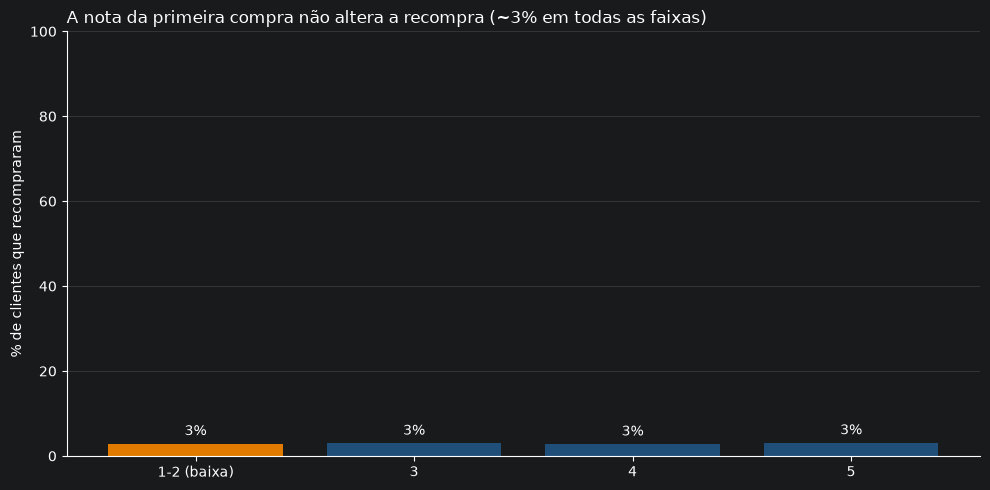

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

taxa_plot = recompra_por_nota["taxa_recompra"] * 100
cores = [COR_DESTAQUE if str(nota).startswith("1") else COR for nota in taxa_plot.index]  # destaque: nota baixa (1-2)

ax.bar(range(len(taxa_plot)), taxa_plot.values, color=cores)
ax.set_xticks(range(len(taxa_plot)))
ax.set_xticklabels(taxa_plot.index)
ax.set_ylabel("% de clientes que recompraram")
ax.set_ylim(0, 100)
ax.set_title("A nota da primeira compra não altera a recompra (~3% em todas as faixas)", loc="left", fontsize=12)

for i, v in enumerate(taxa_plot.values):
    ax.text(i, v + 2, f"{v:.0f}%", ha="center", fontsize=10)

limpa(ax)
plt.tight_layout()
plt.savefig(FIG / "10_recompra_por_nota.png", dpi=150)
plt.show()

## 5. A experiência da 1ª compra: atraso → satisfação → recompra

In [7]:
# Cruza atraso na 1ª compra com recompra
recompra_por_atraso = primeira_compra.groupby(
    pd.cut(primeira_compra["dias_atraso_primeira"], bins=[-np.inf, -5, 0, 5, np.inf], labels=["Muito cedo", "Cedo", "Atrasado leve", "Atraso acima de 5d"])
).agg(
    clientes=("customer_unique_id", "count"),
    recompraram=("recomprou", "sum"),
    nota_media=("nota_primeira", "mean"),
).round(3)
recompra_por_atraso["taxa_recompra"] = (recompra_por_atraso["recompraram"] / recompra_por_atraso["clientes"]).round(3)

print(recompra_por_atraso)

                      clientes  recompraram  nota_media  taxa_recompra
dias_atraso_primeira                                                  
Muito cedo               76856         2419        4.31           0.03
Cedo                      8592          201        4.15           0.02
Atrasado leve             3503           83        3.46           0.02
Atraso acima de 5d        4089          110        1.78           0.03


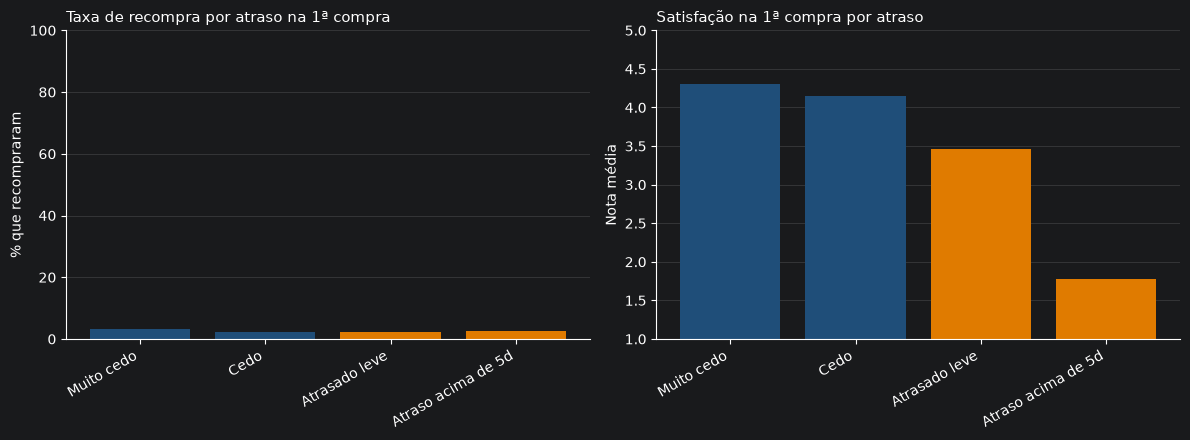

In [8]:
# Visualização: atraso na 1ª compra vs recompra
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico 1: taxa de recompra por atraso
taxa_atraso = recompra_por_atraso["taxa_recompra"] * 100
cores_atr = [COR_DESTAQUE if str(cat).lower().startswith("atras") else COR for cat in taxa_atraso.index]

axes[0].bar(range(len(taxa_atraso)), taxa_atraso.values, color=cores_atr)
axes[0].set_xticks(range(len(taxa_atraso)))
axes[0].set_xticklabels(taxa_atraso.index, rotation=30, ha="right")
axes[0].set_ylabel("% que recompraram")
axes[0].set_ylim(0, 100)
axes[0].set_title("Taxa de recompra por atraso na 1ª compra", loc="left", fontsize=11)

# Gráfico 2: nota média na 1ª compra por atraso
nota_media_atraso = recompra_por_atraso["nota_media"]
axes[1].bar(range(len(nota_media_atraso)), nota_media_atraso.values, color=cores_atr)
axes[1].set_xticks(range(len(nota_media_atraso)))
axes[1].set_xticklabels(nota_media_atraso.index, rotation=30, ha="right")
axes[1].set_ylabel("Nota média")
axes[1].set_ylim(1, 5)
axes[1].set_title("Satisfação na 1ª compra por atraso", loc="left", fontsize=11)

for ax in axes:
    limpa(ax)

plt.tight_layout()
plt.savefig(FIG / "11_atraso_recompra_ligacao.png", dpi=150)
plt.show()

## 6. Análise de cortes: clientes do início vs do fim

Clientes que compraram **cedo em 2017** recompram mais que os de **2018**?
Isso testaria se a "fatiga" ou "queda de qualidade" afeta recompra.

In [9]:
# Mês da primeira compra por cliente, alinhado pela chave customer_unique_id
primeira_data = (
    df.sort_values("order_purchase_timestamp")
      .drop_duplicates("customer_unique_id", keep="first")
      .set_index("customer_unique_id")["mes_compra"]
)
primeira_compra["coorte"] = primeira_compra["customer_unique_id"].map(primeira_data)

# Garantia: todo cliente de primeira_compra deve ter coorte
assert primeira_compra["coorte"].notna().all(), "Clientes sem coorte!"

def faixa_coorte(m):
    if m <= pd.Period("2017-06"):
        return "2017-01 a 2017-06"
    if m <= pd.Period("2017-12"):
        return "2017-07 a 2017-12"
    return "2018-01 a 2018-08"

primeira_compra["coorte_agrupado"] = primeira_compra["coorte"].apply(faixa_coorte)

recompra_por_coorte = primeira_compra.groupby("coorte_agrupado").agg(
    clientes=("customer_unique_id", "count"),
    recompraram=("recomprou", "sum"),
    nota_media=("nota_primeira", "mean"),
)
recompra_por_coorte["taxa_recompra"] = (
    recompra_por_coorte["recompraram"] / recompra_por_coorte["clientes"]
).round(3)

print("Recompra por coorte (período da 1ª compra):")
print(recompra_por_coorte)

Recompra por coorte (período da 1ª compra):
                   clientes  recompraram  nota_media  taxa_recompra
coorte_agrupado                                                    
2017-01 a 2017-06     13983          716        4.14           0.05
2017-07 a 2017-12     29047         1103        4.12           0.04
2018-01 a 2018-08     51673         1055        4.11           0.02


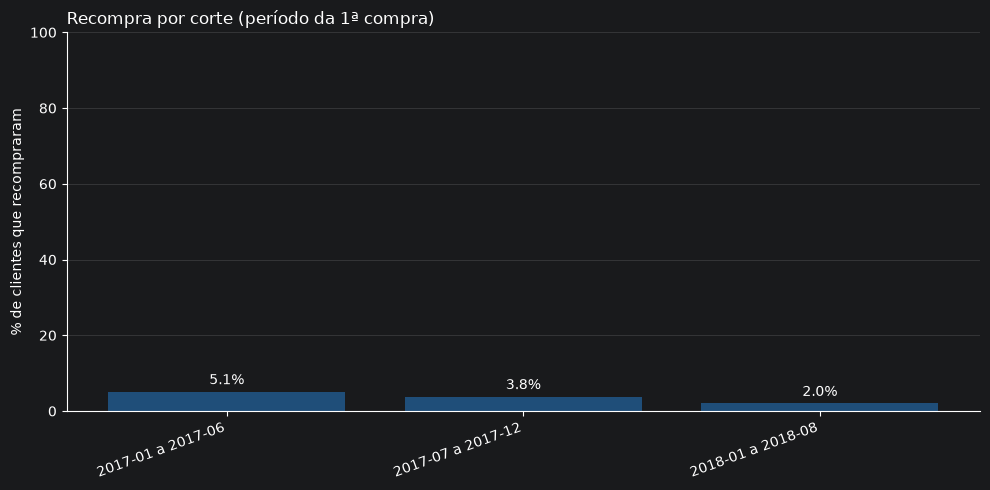

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

taxa_coorte = recompra_por_coorte["taxa_recompra"] * 100
ax.bar(range(len(taxa_coorte)), taxa_coorte.values, color=COR)
ax.set_xticks(range(len(taxa_coorte)))
ax.set_xticklabels(taxa_coorte.index, rotation=20, ha="right")
ax.set_ylabel("% de clientes que recompraram")
ax.set_ylim(0, 100)
ax.set_title("Recompra por corte (período da 1ª compra)", loc="left", fontsize=12)

for i, v in enumerate(taxa_coorte.values):
    ax.text(i, v + 2, f"{v:.1f}%", ha="center", fontsize=10)

limpa(ax)
plt.tight_layout()
plt.savefig(FIG / "12_recompra_por_coorte.png", dpi=150)
plt.show()

## 7. Resumo: o loop satisfação → recompra

In [11]:
# Simples: clientes com nota alta na 1ª compra recompram?
satisfeitos_1a = primeira_compra[primeira_compra["nota_primeira"] >= 4]
insatisfeitos_1a = primeira_compra[primeira_compra["nota_primeira"] < 4]

print("RESUMO DO ATO 3:")
print(f"\nClientes com nota >= 4 na 1ª compra:")
print(f"  Total: {len(satisfeitos_1a):,}")
print(f"  Recompraram: {satisfeitos_1a['recomprou'].sum():,} ({satisfeitos_1a['recomprou'].mean():.1%})")

print(f"\nClientes com nota < 4 na 1ª compra:")
print(f"  Total: {len(insatisfeitos_1a):,}")
print(f"  Recompraram: {insatisfeitos_1a['recomprou'].sum():,} ({insatisfeitos_1a['recomprou'].mean():.1%})")

print(f"\nDiferença: {(satisfeitos_1a['recomprou'].mean() - insatisfeitos_1a['recomprou'].mean())*100:.1f} pontos percentuais")

RESUMO DO ATO 3:

Clientes com nota >= 4 na 1ª compra:
  Total: 73,182
  Recompraram: 2,237 (3.1%)

Clientes com nota < 4 na 1ª compra:
  Total: 20,825
  Recompraram: 611 (2.9%)

Diferença: 0.1 pontos percentuais


## 8. Salvar tabelas de suporte

In [12]:
recompra_por_nota.to_csv(TAB / "recompra_por_nota.csv")
recompra_por_atraso.to_csv(TAB / "recompra_por_atraso.csv")
recompra_por_coorte.to_csv(TAB / "recompra_por_coorte.csv")
print("Tabelas salvas em", TAB)

Tabelas salvas em ..\reports\tabelas
